# Flight School without the gym

The Flight School demo in `bluebird-gymnasium/examples/flight_school_demo.ipynb` controls aircraft through a Gymnasium environment. This notebook does the same task with `bluebird-dt` alone. It makes the simulator, reads the aircraft out of its environment, builds clearances as `Action` objects and gives them to the simulator. Stepping the simulator directly is much faster than stepping the gym environment, which makes it practical to run an hour of traffic many times over.

The task is unchanged. Each aircraft should leave the sector through its exit, at its exit flight level, and no two aircraft should be closer than 5 NM horizontally while they are less than 10 flight levels apart.

1. Make the simulator and step it.
2. Read the aircraft, their routes and their exit coordination.
3. Build the four clearances the gym offers and give them to the simulator.
4. Write an agent that steers each aircraft along its route with heading clearances and takes it to its exit level.
5. Predict what a clearance will do with a rollout, and use that to choose when to give it.
6. Roll out plans of several timed clearances, and let the agent choose between them.

The notebook needs `bluebird-dt` installed from this repository, because the Flight School settings in `bluebird_dt.simulator.presets` are newer than the released package.

## 1. The simulator

In [1]:
# standard library and plotting
import collections
import copy
import itertools
import time

import matplotlib.pyplot as plt

# bluebird-dt: clearances and positions, the radar picture, the scenario, the hand-over test and the settings
from bluebird_dt.core import Action, Pos2D, Pos4D
from bluebird_dt.render import Radar
from bluebird_dt.scenario_manager import Infinite
from bluebird_dt.scenario_manager.outcomm_handler import ExitGate
from bluebird_dt.simulator.presets import FLIGHT_SCHOOL_SETTINGS

# values used throughout the notebook
SEED = 5  # the same seed gives the same traffic
STEP = 6  # seconds of simulated time per step
SECTOR = "sector_xplus"  # the sector we control

`Infinite` is the scenario that keeps spawning traffic. `FLIGHT_SCHOOL_SETTINGS` holds the Flight School settings as keyword arguments: the X-shaped sector, two aircraft to start with, traffic between FL200 and FL350, and how fast new aircraft appear. The last three options stop the simulator writing log files.

In [2]:
def make_sim(seed=SEED):
    """A new Flight School simulator with an hour of traffic."""
    return Infinite.setup(
        # which traffic, and for how long
        random_seed=seed,
        total_time_seconds=3600.0,
        # the Flight School sector and traffic settings
        **FLIGHT_SCHOOL_SETTINGS,
        # write no log files
        save_log_to_file=False,
        save_csv=False,
        autosave_interval=None,
    )


# make a simulator and look at where it starts
sim = make_sim()
environment = sim.manager.environment

print(f"time {environment.time:.0f} s, {len(environment.aircraft)} aircraft")

time 6 s, 2 aircraft


`sim.evolve(STEP)` moves every aircraft forward by 6 seconds, adds new traffic and hands over aircraft that have left the sector. That is all a step does, so it is quick.

In [3]:
# time 100 steps
start = time.perf_counter()
for _ in range(100):
    sim.evolve(STEP)
seconds = time.perf_counter() - start

# the time per step, and where the simulator has got to
print(f"100 steps took {seconds:.2f} s, which is {1000 * seconds / 100:.0f} ms a step")
print(f"time {environment.time:.0f} s, {len(environment.aircraft)} aircraft")

sim.close()

100 steps took 0.54 s, which is 5 ms a step
time 606 s, 6 aircraft


For comparison, a step of the gym environment took about 140 ms on the same machine. Each of its steps also builds an observation and a reward for every aircraft.

## 2. Reading the state

Everything about the current state is in `sim.manager.environment`: the time, the aircraft (a dictionary from callsign to `Aircraft`) and the airspace with its sectors and fixes. We make a new simulator here. The seed is the same, so the traffic is the same.

In [4]:
# a new simulator with the same seed
sim = make_sim()
environment = sim.manager.environment

# print what the environment holds for each aircraft
for callsign, aircraft in environment.aircraft.items():
    # the agreement with the next sector: the exit fix and the exit level
    coordination = environment.exit_coordination(SECTOR, callsign)

    print(f"{callsign} ({aircraft.aircraft_type})")
    print(
        f"  position: lat {aircraft.lat:.3f}, lon {aircraft.lon:.3f}, FL{aircraft.fl:.0f}, heading {aircraft.heading:.1f}"
    )
    print(f"  selected: FL{aircraft.selected_fl:.0f}, heading {aircraft.selected_instructions.heading}")
    print(
        f"  route:    {' '.join(aircraft.flight_plan.route.filed)} (following it: {aircraft.selected_instructions.on_route})"
    )
    print(f"  exit:     {coordination.fix} at FL{coordination.fl:.0f}")

AIR-00 (B753)
  position: lat 0.713, lon 0.803, FL270, heading 225.2
  selected: FL270, heading None
  route:    SWIFT QUAIL MACAW ALB GOOSE PEL (following it: False)
  exit:     GOOSE at FL280
AIR-01 (B753)
  position: lat 0.530, lon -0.765, FL290, heading 134.8
  selected: FL290, heading None
  route:    PEL GOOSE ALB MACAW QUAIL SWIFT (following it: False)
  exit:     QUAIL at FL260


Each aircraft has:

- its position: `lat`, `lon`, `fl` and `heading`;
- the values it has been cleared to: `selected_fl` and `selected_instructions.heading`. The selected heading is `None` until a heading clearance is given, and the aircraft keeps flying its current heading;
- its route, a list of fix names in `flight_plan.route.filed`, and whether it is following that route, in `selected_instructions.on_route`. Flight School aircraft are not following their routes. Section 4 comes back to this;
- its exit coordination, from `environment.exit_coordination(sector, callsign)`. This is the agreement with the next sector: the fix the aircraft leaves by (`fix`) and the exit flight level (`fl`, the XFL). The hand-over only succeeds if the aircraft crosses the side of the sector nearest that fix at exactly that level.

The airspace gives the sector, which can test whether a position is inside it, and the position of each fix.

In [5]:
# the sector we control, and the position of every fix by name
sector = environment.airspace.sectors[SECTOR]
fixes = environment.airspace.fixes.places

# the aircraft that can be given clearances now
print("controllable:", environment.controllable_aircraft(SECTOR))

# for each of them: is it inside the sector, and how far is it from its exit fix?
for callsign in environment.controllable_aircraft(SECTOR):
    aircraft = environment.aircraft[callsign]
    exit_fix = fixes[environment.exit_coordination(SECTOR, callsign).fix]
    inside = sector.contains(aircraft.pos3d())

    print(f"{callsign}: inside the sector {inside}, {aircraft.pos2d().distance(exit_fix):.0f} NM from its exit fix")

controllable: ['AIR-00', 'AIR-01']
AIR-00: inside the sector False, 84 NM from its exit fix
AIR-01: inside the sector False, 89 NM from its exit fix


Aircraft appear just outside the sector and can be controlled straight away, so clearances can be given before they cross the boundary.

`Radar` draws the environment. Each label shows the callsign and exit level on the first line, and the current and selected level on the second.

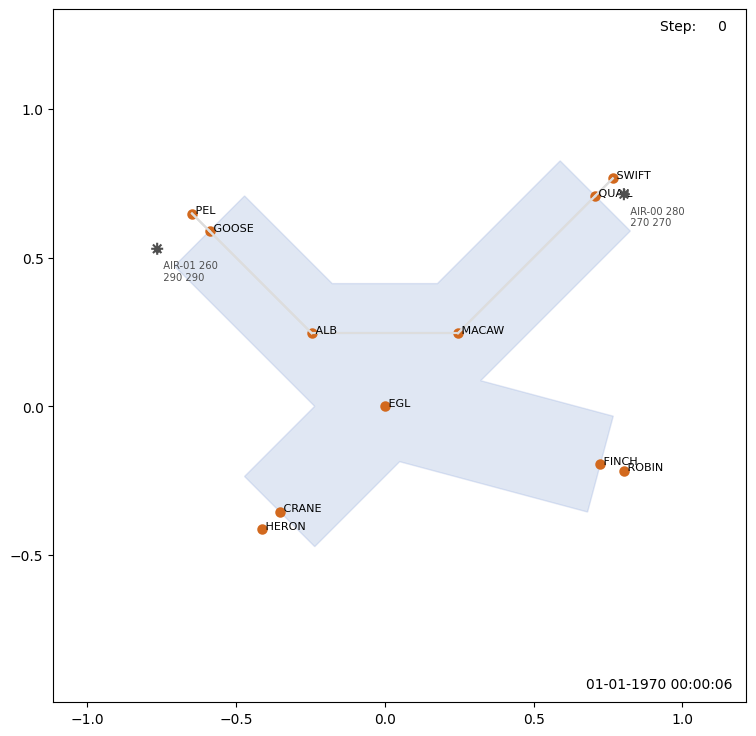

In [6]:
def draw_radar(environment):
    """Draw the sector, the fixes and every aircraft, and return the axes so that more can be drawn on top."""
    # a radar picture centred on the sector
    radar = Radar(centre=Pos2D(lat=0.17, lon=0.05), scale=140, aspect_ratio=1.0, sector_name=SECTOR, auto_display=False)

    figure, ax = radar.draw(environment)
    return ax


draw_radar(environment)
plt.show()

## 3. The four clearances

A clearance is an `Action`: a callsign, a kind and a value. The simulator accepts many kinds, such as a direct route to a fix or a speed. The gym offers four: turn 10° left, turn 10° right, climb 10 flight levels and descend 10 flight levels, each measured from the value selected so far. We keep to those four, so everything the agents in this notebook do, a gym agent could do too.

Each clearance is a function that takes an aircraft and returns the `Action`.

A turn is a `change_heading_to` clearance, which carries the new heading itself: the selected heading plus or minus 10°. The gym builds its turns the same way, in `heading_left` and `heading_right` of `bluebird_gymnasium/actions/simple/heading.py`. The simulator also accepts `change_heading_by`, but that measures the turn from the heading the aircraft is flying at that moment. Two of those on successive steps turn an aircraft 19° and not 20°, because it has not finished the first turn when the second arrives. The level clearances are `change_flight_level_to` for the same reason.

In [7]:
def selected_heading(aircraft):
    """The heading the aircraft was last cleared to, or the heading it is flying if it has had no heading clearance."""
    heading = aircraft.selected_instructions.heading

    return aircraft.heading if heading is None else heading


def turn_left(aircraft):
    """Turn to the heading 10 degrees left of the selected heading."""
    return Action(aircraft.callsign, "change_heading_to", round(selected_heading(aircraft) - 10) % 360)


def turn_right(aircraft):
    """Turn to the heading 10 degrees right of the selected heading."""
    return Action(aircraft.callsign, "change_heading_to", round(selected_heading(aircraft) + 10) % 360)


def climb(aircraft):
    """Climb to the level 10 flight levels above the selected level."""
    return Action(aircraft.callsign, "change_flight_level_to", aircraft.selected_fl + 10)


def descend(aircraft):
    """Descend to the level 10 flight levels below the selected level."""
    return Action(aircraft.callsign, "change_flight_level_to", aircraft.selected_fl - 10)


# build each of the four clearances for one aircraft and print the Action
aircraft = environment.aircraft["AIR-00"]

for clearance in (turn_left, turn_right, climb, descend):
    action = clearance(aircraft)
    print(f"{clearance.__name__:10s} -> Action({action.callsign!r}, {action.kind!r}, {action.value})")

turn_left  -> Action('AIR-00', 'change_heading_to', 215)
turn_right -> Action('AIR-00', 'change_heading_to', 235)
climb      -> Action('AIR-00', 'change_flight_level_to', 280)
descend    -> Action('AIR-00', 'change_flight_level_to', 260)


`sim.action` takes the list of actions for this step, and the next `sim.evolve` passes them to the pilots. An aircraft can take one heading clearance and one level clearance in a step. Here AIR-00 is told to climb and to turn right.

In [8]:
def report(aircraft):
    """Print where the aircraft is and what it has been cleared to."""
    print(
        f"t {environment.time:2.0f} s: FL{aircraft.fl:.0f} (selected FL{aircraft.selected_fl:.0f}), "
        f"heading {aircraft.heading:.1f} (selected {selected_heading(aircraft):.1f})"
    )


# the state before any clearance
report(aircraft)

# give AIR-00 two clearances at once: climb 10 flight levels and turn 10 degrees right
sim.action([climb(aircraft), turn_right(aircraft)])

# step the simulator and watch the aircraft respond
for _ in range(8):
    sim.evolve(STEP)
    report(environment.aircraft["AIR-00"])

sim.close()

t  6 s: FL270 (selected FL270), heading 225.2 (selected 225.2)
t 12 s: FL270 (selected FL280), heading 225.2 (selected 235.0)
t 18 s: FL272 (selected FL280), heading 234.2 (selected 235.0)
t 24 s: FL274 (selected FL280), heading 235.0 (selected 235.0)
t 30 s: FL276 (selected FL280), heading 235.0 (selected 235.0)
t 36 s: FL278 (selected FL280), heading 235.0 (selected 235.0)
t 42 s: FL280 (selected FL280), heading 235.0 (selected 235.0)
t 48 s: FL280 (selected FL280), heading 235.0 (selected 235.0)
t 54 s: FL280 (selected FL280), heading 235.0 (selected 235.0)


The pilot takes the clearances at the end of the first step, which is when the selected values change. The aircraft starts to climb and turn on the step after that. It turns about 9° a step and climbs 2 flight levels a step, so a 10 FL clearance takes 5 steps.

## 4. An agent that steers along the route with headings

Flight School aircraft do not follow their routes. Each one appears several miles to one side of its route, flying a heading parallel to the first leg, and it keeps that heading until a clearance gives it another. That is why the printout in section 2 says `following it: False`.

In ATC these are two different things. An aircraft that is following its route navigates from fix to fix by itself and needs no heading clearances. An aircraft on a heading flies that heading until the controller gives it another, wherever its route goes. None of the four clearances puts an aircraft on its route, so the agents in this notebook never use route following. They turn each aircraft with heading clearances, 10° at a time, towards the next fix on its route. The aircraft flies alongside its route and then close to it, and leaves by the right side of the sector, but it is on a heading the whole time.

An agent here is an object with an `act()` method. It looks at the environment and returns the list of actions for this step. Running it takes two lines:

```python
sim.action(agent.act())
sim.evolve(STEP)
```

The simplest agent gives no clearances.

In [9]:
class NoAgent:
    """Gives no clearances."""

    def __init__(self, sim):
        self.environment = sim.manager.environment

    def act(self):
        return []

`HeadingAgent` has two rules, which it applies to every aircraft it controls:

- `level` moves the selected level one clearance towards the exit level;
- `turn` moves the selected heading one clearance towards the direction of the next fix on the route, once the aircraft is inside the sector.

A rule returns one of the four clearance functions, or `None` when nothing is needed. The rollouts in section 5 use the rules in the same form.

`next_fix` finds the first fix on the route that the aircraft has not passed. An aircraft has passed a fix when it is on the same side of it as the following fix. The test is approximate, and an aircraft can pass well to one side of a fix. That is fine here: the fixes only give the agent a direction to steer by, and the task only needs the aircraft to leave by its exit.

In [10]:
def angle(a, b):
    """The difference a - b between two directions, from -180 to 180 degrees."""
    return (a - b + 180) % 360 - 180


def next_fix(environment, aircraft):
    """The first fix on the route of the aircraft that it has not passed."""
    # the positions of the fixes on the route, in order
    places = environment.airspace.fixes.places
    route = [places[name] for name in aircraft.flight_plan.route.filed]

    position = aircraft.pos2d()

    # the aircraft has not passed a fix while it is on the other side of it from the following fix
    for fix, following in zip(route, route[1:]):
        if abs(angle(fix.bearing_to(position), fix.bearing_to(following))) > 90:
            return fix

    # only the last fix is left
    return route[-1]


class HeadingAgent:
    """Steers each aircraft along its route with heading clearances, and takes it to its exit level."""

    def __init__(self, sim):
        self.sim = sim
        self.environment = sim.manager.environment
        self.sector = self.environment.airspace.sectors[SECTOR]

    def act(self):
        """The clearances for this step: at most one level and one heading clearance for each aircraft."""
        actions = []

        for callsign in self.environment.controllable_aircraft(SECTOR):
            aircraft = self.environment.aircraft[callsign]

            # ask each rule for a clearance, and build the Action for each one it gives
            for clearance in (self.level(aircraft), self.turn(aircraft)):
                if clearance is not None:
                    actions.append(clearance(aircraft))

        return actions

    def level(self, aircraft):
        """Climb or descend until the selected level is the exit level."""
        exit_level = self.environment.exit_coordination(SECTOR, aircraft.callsign).fl

        if aircraft.selected_fl < exit_level:
            return climb
        if aircraft.selected_fl > exit_level:
            return descend
        return None

    def turn(self, aircraft):
        """Turn until the selected heading is within 5 degrees of the direction to the next fix."""
        # no heading clearances until the aircraft is inside the sector
        if not self.sector.contains_laterally(aircraft.pos2d()):
            return None

        # how far the direction to the next fix is to the right of the selected heading
        to_fix = aircraft.pos2d().bearing_to(next_fix(self.environment, aircraft))
        off = angle(to_fix, selected_heading(aircraft))

        if off > 5:
            return turn_right
        if off < -5:
            return turn_left
        return None

To score an agent we check the two requirements at every step.

- `lost_pairs` lists the pairs of aircraft that are closer than 5 NM and less than 10 flight levels apart. The level difference is rounded, because levels carry floating-point noise during a climb and aircraft exactly 10 flight levels apart are separated.
- `update_outcomes` follows each aircraft through the sector. The simulator changes `current_sector` when it hands an aircraft over, which needs the right side of the sector and the exit level, so that is a right exit. An aircraft that has left the sector and is still not handed over a step later made a wrong exit.

`run` flies an hour of traffic (600 steps) with an agent and counts both.

In [11]:
def too_close(a, b):
    """Are two positions less than 10 flight levels and less than 5 NM apart?"""
    return round(abs(a.fl - b.fl), 3) < 10 and a.distance(b) < 5


def lost_pairs(environment):
    """The pairs of aircraft we control that have lost separation."""
    ours = [environment.aircraft[callsign] for callsign in environment.controllable_aircraft(SECTOR)]

    return [(a.callsign, b.callsign) for a, b in itertools.combinations(ours, 2) if too_close(a.pos3d(), b.pos3d())]


def update_outcomes(outcomes, environment):
    """Note where each aircraft has got to on its way through the sector."""
    sector = environment.airspace.sectors[SECTOR]

    for callsign, aircraft in environment.aircraft.items():
        before = outcomes.get(callsign)

        if aircraft.current_sector != SECTOR:
            # the simulator has handed the aircraft over
            outcomes[callsign] = "right exit"
        elif sector.contains(aircraft.pos3d()):
            outcomes[callsign] = "in sector"
        elif before == "in sector":
            # the first step outside the sector: the hand-over can still come
            outcomes[callsign] = "leaving"
        elif before == "leaving":
            # still not handed over a step later
            outcomes[callsign] = "wrong exit"


def run(agent_class, seed=SEED, steps=600):
    """Fly traffic with an agent, and count the exits and the pairs that lost separation."""
    # a new simulator, and an agent for it
    sim = make_sim(seed)
    agent = agent_class(sim)
    environment = sim.manager.environment

    # outcomes: callsign -> where the aircraft has got to; losses: pair of callsigns -> the times it was too close
    outcomes, losses = {}, {}

    start = time.perf_counter()
    for _ in range(steps):
        # ask the agent for this step's clearances and give them to the simulator
        sim.action(agent.act())

        # move everything forward by one step
        sim.evolve(STEP)

        # note where each aircraft is on its way through the sector, and any pairs that are too close
        update_outcomes(outcomes, environment)
        for pair in lost_pairs(environment):
            losses.setdefault(pair, []).append(environment.time)
    seconds = time.perf_counter() - start

    sim.close()

    # count the aircraft by outcome
    counts = collections.Counter(outcomes.values())

    return {
        "agent": agent,
        "aircraft": len(outcomes),
        "right exit": counts["right exit"],
        "wrong exit": counts["wrong exit"],
        "pairs lost": len(losses),
        "seconds": round(seconds, 1),
        "losses": losses,
    }


# the columns of the results table, and the result of each agent by name
COLUMNS = ("aircraft", "right exit", "wrong exit", "pairs lost", "seconds")
results = {}


def show_results():
    """Print a row of the results table for each agent run so far."""
    print(f"{'agent':16s}" + "".join(f"{column:>12s}" for column in COLUMNS))

    for name, result in results.items():
        print(f"{name:16s}" + "".join(f"{result[column]:12}" for column in COLUMNS))


# fly an hour of traffic with each of the two agents
for agent_class in (NoAgent, HeadingAgent):
    results[agent_class.__name__] = run(agent_class)

show_results()

agent               aircraft  right exit  wrong exit  pairs lost     seconds
NoAgent                   35           0          32           1         7.3
HeadingAgent              33          29           0           5         8.4


The `aircraft` column counts the aircraft that entered the sector, and `pairs lost` the pairs that lost separation at some point. Aircraft in neither exit column were still inside the sector when the hour ended. The number of aircraft differs slightly between agents: even with the same seed, later traffic depends on what the earlier aircraft were told to do.

With no clearances, every aircraft that leaves makes a wrong exit: it never turns and never changes level. `HeadingAgent` hands over every aircraft that leaves, but it loses separation between these pairs:

In [12]:
# when each pair was too close
for (a, b), times in results["HeadingAgent"]["losses"].items():
    print(f"{a} and {b}: from t {times[0]:.0f} s to t {times[-1]:.0f} s")

AIR-04 and AIR-05: from t 1038 s to t 1074 s
AIR-03 and AIR-08: from t 1152 s to t 1188 s
AIR-19 and AIR-20: from t 2268 s to t 2316 s
AIR-16 and AIR-17: from t 2304 s to t 2394 s
AIR-18 and AIR-25: from t 2826 s to t 2850 s


`HeadingAgent` changes level as soon as an aircraft appears and never looks at the other aircraft. To do better it has to know what a clearance will lead to before giving it.

## 5. Rollouts: predicting what a clearance will do

A rollout copies one aircraft and moves the copy forward step by step, using the simulator's own predictor, which moves aircraft, and the copy's pilot, which applies clearances. The real aircraft is not touched. These are the objects the simulator itself uses in `evolve`, so the rollout gives the path the simulator will produce. Section 6 checks this.

The copy can be given clearances in two ways:

- a plan, which is a list of `(wait, clearance)` pairs: wait that many seconds after the previous item, then give the clearance. `schedule` turns the waits into times, and `due` picks out the clearances for one step;
- rules, such as `agent.turn`, which are asked for a clearance at every step.

The order inside the loop is the simulator's: clearances are built from the state at the start of the step, the aircraft moves, and then its pilot takes the clearances.

In [13]:
def schedule(plan, start):
    """Turn a plan, a list of (wait, clearance), into a list of (time to give it, clearance)."""
    timed, when = [], start

    for wait, clearance in plan:
        when += wait
        timed.append((when, clearance))

    return timed


def due(timed, now):
    """The clearances of a timed plan that fall in the step starting at `now`."""
    return [clearance for when, clearance in timed if now <= when < now + STEP]


def rollout(sim, aircraft, plan=(), rules=(), seconds=1500):
    """Predict the path of an aircraft, from now until it leaves the sector."""
    environment, predictor = sim.manager.environment, sim.manager.predictor
    sector = environment.airspace.sectors[SECTOR]

    # a copy of the aircraft, in a copy of the environment that holds only that aircraft
    what_if = copy.deepcopy(aircraft)
    shadow = copy.copy(environment)
    shadow.aircraft = {what_if.callsign: what_if}

    # the plan with its waits turned into times
    timed = schedule(plan, environment.time)

    # the path starts at the current position
    path = [Pos4D(what_if.lat, what_if.lon, what_if.fl, environment.time)]
    was_inside = False

    for step in range(seconds // STEP):
        shadow.time = environment.time + step * STEP

        # this step's clearances: those the plan has due, and one from each rule
        clearances = due(timed, shadow.time) + [rule(what_if) for rule in rules]
        actions = [clearance(what_if) for clearance in clearances if clearance is not None]

        # move the copy, then let its pilot take the clearances
        predictor.predict_aircraft(
            what_if, STEP, environment_time=shadow.time, wind_field=environment.wind_field, deepcopy_aircraft=False
        )
        what_if.pilot.receive_actions(actions, shadow)
        what_if.pilot.process_actions(shadow)

        # add the new position to the path
        path.append(Pos4D(what_if.lat, what_if.lon, what_if.fl, shadow.time + STEP))

        # stop once the copy has left the sector
        inside = sector.contains_laterally(what_if.pos2d())
        if was_inside and not inside:
            break
        was_inside = inside

    return path

A path is a list of `Pos4D` points (latitude, longitude, flight level and time), from the current position to the first point outside the sector. Two functions read a path:

- `predicted_outcome` applies the hand-over test to the last step: did it cross the exit gate, the side of the sector nearest the exit fix, at the exit level?
- `first_loss` gives the first time at which two paths are too close, or `None`.

In [14]:
def exit_gate(environment, fix_name):
    """The side of the sector nearest a fix, as the gate an aircraft has to cross to be handed over."""
    area = environment.airspace.sectors[SECTOR].volumes[0].area

    # the two ends of the side of the sector nearest the fix
    (lon0, lat0), (lon1, lat1) = area.nearest_segment_to_point(environment.airspace.fixes.places[fix_name])

    return ExitGate.new(start_position=Pos2D(lon=lon0, lat=lat0), end_position=Pos2D(lon=lon1, lat=lat1))


def predicted_outcome(environment, callsign, path):
    """How a predicted path ends: "right exit", "wrong exit" or "still inside"."""
    sector = environment.airspace.sectors[SECTOR]

    # did the last step of the path take the aircraft out of the sector?
    left = len(path) > 1 and sector.contains_laterally(path[-2]) and not sector.contains_laterally(path[-1])
    if not left:
        return "still inside"

    # the hand-over test: the last step crossed the exit gate, and the aircraft was at the exit level
    coordination = environment.exit_coordination(SECTOR, callsign)
    crossed = exit_gate(environment, coordination.fix).is_crossed(path[-2], path[-1])

    return "right exit" if crossed and path[-1].fl == coordination.fl else "wrong exit"


def first_loss(path_a, path_b):
    """The first time at which two paths are too close, or None."""
    # the points of the second path by time
    at = {point.time: point for point in path_b}

    # compare the two paths at each time they share
    for point in path_a:
        other = at.get(point.time)
        if other is not None and too_close(point, other):
            return point.time

    return None


# colours for the plots
BLUE, ORANGE = "#2a78d6", "#eb6834"


def draw_path(ax, path, **style):
    """Draw a path on a radar picture."""
    ax.plot([point.lon for point in path], [point.lat for point in path], **{"linewidth": 2, **style})

### Where will an aircraft go?

AIR-01 enters from the north-west at FL290 and should leave by QUAIL at FL260. We predict its path with no clearances at all, and with the two rules of `HeadingAgent`.

no clearances: wrong exit at t 666 s, FL290
heading agent rules: right exit at t 1080 s, FL260


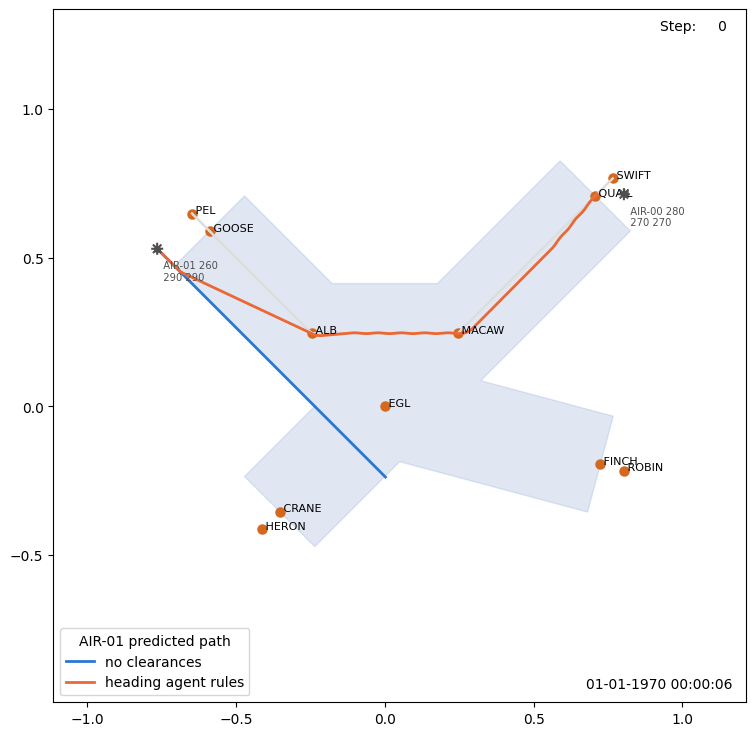

In [15]:
# a new simulator, an agent to take the rules from, and the aircraft to predict
sim = make_sim()
environment = sim.manager.environment
agent = HeadingAgent(sim)
aircraft = environment.aircraft["AIR-01"]

# two rollouts: no clearances at all, and the two rules of the agent at every step
paths = {
    "no clearances": rollout(sim, aircraft),
    "heading agent rules": rollout(sim, aircraft, rules=[agent.level, agent.turn]),
}

# how each predicted path ends
for name, path in paths.items():
    outcome = predicted_outcome(environment, "AIR-01", path)
    print(f"{name}: {outcome} at t {path[-1].time:.0f} s, FL{path[-1].fl:.0f}")

# draw both paths on the radar picture
ax = draw_radar(environment)
for (name, path), color in zip(paths.items(), (BLUE, ORANGE)):
    draw_path(ax, path, color=color, label=name)

ax.legend(title="AIR-01 predicted path", loc="lower left")
plt.show()

With no clearances AIR-01 keeps the heading it appeared on, parallel to the first leg of its route, and leaves through the wrong side of the sector, still at FL290. Under the rules it is turned towards each fix of its route in turn and leaves by QUAIL at FL260. The path wobbles a little because the heading changes 10° at a time.

### When should it descend?

`repeat` and `level_change` build plans. AIR-01 has to descend 30 flight levels, which is three clearances on successive steps. The rollout tells us how long the first of them can wait: the turn rule steers as before, and the plan starts the descent after different waits.

In [16]:
def repeat(clearance, count, wait=0):
    """A plan that gives one clearance `count` times on successive steps, the first after `wait` seconds."""
    return [(wait if i == 0 else STEP, clearance) for i in range(count)]


def level_change(from_level, to_level, wait=0):
    """A plan that changes level 10 flight levels at a time, starting after `wait` seconds."""
    clearance = climb if to_level > from_level else descend

    return repeat(clearance, round(abs(to_level - from_level) / 10), wait)


exit_level = environment.exit_coordination(SECTOR, "AIR-01").fl

# start the descent after different waits, and see how each predicted path ends
for wait in (0, 300, 600, 900, 960, 990, 1020):
    # the plan descends, and the turn rule steers
    plan = level_change(aircraft.selected_fl, exit_level, wait)
    path = rollout(sim, aircraft, plan, rules=[agent.turn])

    outcome = predicted_outcome(environment, "AIR-01", path)
    print(f"descend after {wait:4d} s: {outcome}, leaves at FL{path[-1].fl:.0f}")

descend after    0 s: right exit, leaves at FL260
descend after  300 s: right exit, leaves at FL260
descend after  600 s: right exit, leaves at FL260


descend after  900 s: right exit, leaves at FL260
descend after  960 s: right exit, leaves at FL260
descend after  990 s: wrong exit, leaves at FL264


descend after 1020 s: wrong exit, leaves at FL274


The descent can start at any time in the next 960 seconds. Any later and the aircraft is still descending when it leaves. So there is a window of 16 minutes, and the agent can use it to keep out of the way of other aircraft.

### Choosing a time that avoids another aircraft

The first pair `HeadingAgent` lost was AIR-04 and AIR-05. We run the agent until AIR-05 appears, and predict the path of AIR-05 and of every other aircraft under its rules.

t 546 s: AIR-05 is at FL200 and should leave at FL210


predicted loss with AIR-04 at t 1038 s: FL210 and FL210, 4.1 NM apart


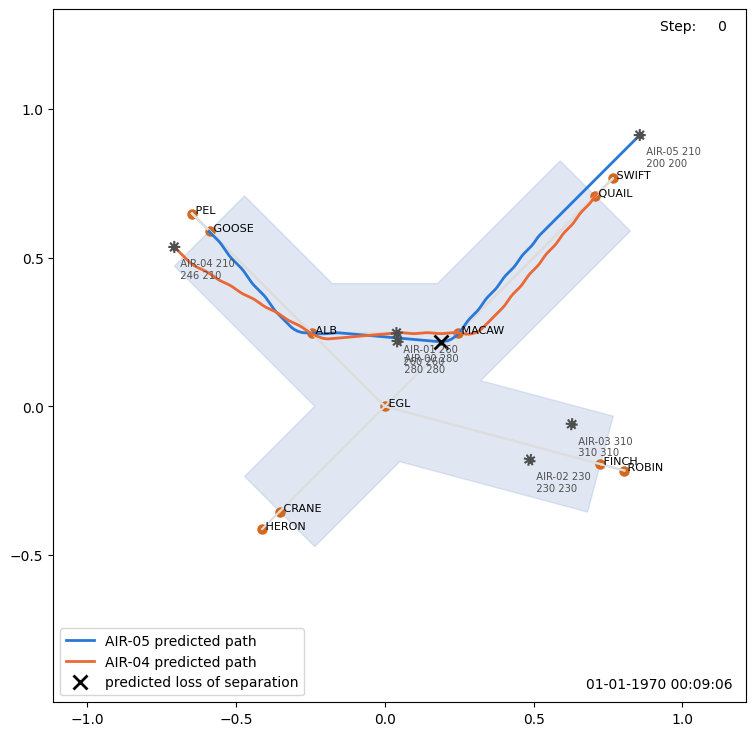

In [17]:
# run the agent until AIR-05 appears
while "AIR-05" not in environment.aircraft:
    sim.action(agent.act())
    sim.evolve(STEP)

aircraft = environment.aircraft["AIR-05"]
exit_level = environment.exit_coordination(SECTOR, "AIR-05").fl
print(f"t {environment.time:.0f} s: AIR-05 is at FL{aircraft.fl:.0f} and should leave at FL{exit_level:.0f}")

# the predicted path of every other aircraft under the rules of the agent
others = {
    callsign: rollout(sim, environment.aircraft[callsign], rules=[agent.level, agent.turn])
    for callsign in environment.controllable_aircraft(SECTOR)
    if callsign != "AIR-05"
}

# the predicted path of AIR-05 under the same rules
path = rollout(sim, aircraft, rules=[agent.level, agent.turn])

# compare it with each of the others
for callsign, other in others.items():
    when = first_loss(path, other)

    if when is not None:
        # where the two aircraft are at that time
        ours, theirs = (next(point for point in points if point.time == when) for points in (path, other))
        print(
            f"predicted loss with {callsign} at t {when:.0f} s: FL{ours.fl:.0f} and FL{theirs.fl:.0f}, {ours.distance(theirs):.1f} NM apart"
        )

# draw the predicted paths of AIR-05 and AIR-04
ax = draw_radar(environment)
for (callsign, points), color in zip({"AIR-05": path, "AIR-04": others["AIR-04"]}.items(), (BLUE, ORANGE)):
    draw_path(ax, points, color=color, label=f"{callsign} predicted path")

# mark where AIR-05 is when the two first come too close
when = first_loss(path, others["AIR-04"])
draw_path(
    ax,
    [point for point in path if point.time == when],
    color="black",
    marker="x",
    markersize=10,
    markeredgewidth=2,
    linestyle="",
    label="predicted loss of separation",
)

ax.legend(loc="lower left")
plt.show()

The rollouts predict the loss that happened in the run above. Now we try the climb of AIR-05 after different waits, and compare each predicted path with the paths of the other aircraft.

In [18]:
# start the climb of AIR-05 after each wait from 0 to 600 seconds
for wait in range(0, 601, 60):
    # the plan climbs, and the turn rule steers
    plan = level_change(aircraft.selected_fl, exit_level, wait)
    path = rollout(sim, aircraft, plan, rules=[agent.turn])

    # how the path ends, and which of the other aircraft it comes too close to
    outcome = predicted_outcome(environment, "AIR-05", path)
    losses = [callsign for callsign, other in others.items() if first_loss(path, other) is not None]

    print(f"climb after {wait:3d} s: {outcome}, loss of separation with {', '.join(losses) or 'nobody'}")

sim.close()

climb after   0 s: right exit, loss of separation with AIR-04
climb after  60 s: right exit, loss of separation with AIR-04
climb after 120 s: right exit, loss of separation with AIR-04
climb after 180 s: right exit, loss of separation with AIR-04


climb after 240 s: right exit, loss of separation with AIR-04
climb after 300 s: right exit, loss of separation with AIR-04
climb after 360 s: right exit, loss of separation with AIR-04
climb after 420 s: right exit, loss of separation with AIR-04


climb after 480 s: right exit, loss of separation with AIR-04
climb after 540 s: right exit, loss of separation with nobody
climb after 600 s: right exit, loss of separation with nobody


AIR-04 is at FL210 when the two meet. A climb that starts in the first 480 seconds has AIR-05 at FL210 too, or on its way there. Waiting 540 seconds keeps AIR-05 at FL200, 10 flight levels below, until AIR-04 has passed, and it still leaves at its exit level.

### An agent that looks ahead

`LookaheadAgent` does this for every aircraft. When an aircraft first appears, the agent tries starting its level change after 0, 60, 120 and up to 600 seconds. It rolls out each candidate with the turn rule, and takes the first one that is predicted to make a right exit without coming too close to the predicted path of any aircraft planned earlier. It keeps the chosen path, so that later aircraft are planned around it. If no candidate works it takes the first.

Steering is still done by the turn rule at every step. Only the level clearances come from the plan.

In [19]:
def describe(plan):
    """A plan in words, with repeated clearances on successive steps grouped."""
    # each part is [the wait before it, the clearance, how many times it is given]
    parts = []

    for wait, clearance in plan:
        if parts and wait == STEP and parts[-1][1] is clearance:
            # the same clearance again on the next step: count it with the last part
            parts[-1][2] += 1
        else:
            parts.append([wait, clearance, 1])

    return ", ".join(
        (f"wait {wait} s, " if wait else "") + f"{clearance.__name__} x{count}" for wait, clearance, count in parts
    )


class LookaheadAgent(HeadingAgent):
    """A HeadingAgent that uses rollouts to choose when each aircraft changes level."""

    # the waits to try before the level change, in seconds
    WAITS = range(0, 601, 60)

    def __init__(self, sim):
        super().__init__(sim)

        self.plans = {}  # callsign -> (time the plan was made, plan)
        self.timed = {}  # callsign -> the plan as (time, clearance) pairs
        self.paths = {}  # callsign -> predicted path under the plan

        self.rollouts = 0  # how many rollouts the agent has run
        self.no_plan = []  # aircraft for which no candidate worked

    def act(self):
        # choose a plan for each aircraft that has just appeared
        for callsign in self.environment.controllable_aircraft(SECTOR):
            if callsign not in self.plans:
                plan, self.paths[callsign] = self.choose_plan(self.environment.aircraft[callsign])
                self.plans[callsign] = (self.environment.time, plan)
                self.timed[callsign] = schedule(plan, self.environment.time)

        # the two rules do the rest: `level` now reads the plan, and `turn` is unchanged
        return super().act()

    def level(self, aircraft):
        """The level clearance that the plan of the aircraft has due on this step, if any."""
        clearances = due(self.timed[aircraft.callsign], self.environment.time)

        return clearances[0] if clearances else None

    def candidate_plans(self, aircraft):
        """The plans to try, in order: the change to the exit level after each wait."""
        start = aircraft.selected_fl
        end = self.environment.exit_coordination(SECTOR, aircraft.callsign).fl

        # an aircraft that is already at its exit level has one candidate, the empty plan
        return [level_change(start, end, wait) for wait in self.WAITS] if start != end else [[]]

    def choose_plan(self, aircraft):
        """The first candidate plan that is predicted to work, with its predicted path."""
        candidates = []

        for plan in self.candidate_plans(aircraft):
            # predict the path under this plan, with the turn rule steering
            self.rollouts += 1
            path = rollout(self.sim, aircraft, plan, rules=[self.turn])
            candidates.append((plan, path))

            # take the plan if it makes a right exit and keeps clear of every path planned so far
            right = predicted_outcome(self.environment, aircraft.callsign, path) == "right exit"
            if right and all(first_loss(path, other) is None for other in self.paths.values()):
                return plan, path

        # no candidate worked, so take the first
        self.no_plan.append(aircraft.callsign)
        return candidates[0]


def show_plans(agent):
    """Print how many rollouts an agent ran, and the plans in which an aircraft waits."""
    print(
        f"{agent.rollouts} rollouts for {len(agent.plans)} aircraft; no candidate worked for {agent.no_plan or 'none'}"
    )

    print("plans that wait:")
    for callsign, (start, plan) in agent.plans.items():
        if any(wait > STEP for wait, _ in plan):
            print(f"  {callsign}, planned at t {start:.0f} s: {describe(plan)}")


# fly an hour of traffic with the agent and add it to the results table
results["LookaheadAgent"] = run(LookaheadAgent)

show_results()
show_plans(results["LookaheadAgent"]["agent"])

agent               aircraft  right exit  wrong exit  pairs lost     seconds
NoAgent                   35           0          32           1         7.3
HeadingAgent              33          29           0           5         8.4
LookaheadAgent            33          29           0           1        11.7
52 rollouts for 33 aircraft; no candidate worked for ['AIR-25']
plans that wait:
  AIR-05, planned at t 546 s: wait 540 s, climb x1
  AIR-08, planned at t 888 s: wait 60 s, climb x10
  AIR-17, planned at t 1962 s: wait 180 s, descend x10
  AIR-20, planned at t 2166 s: wait 360 s, descend x7


Four of the five losses are gone. Most aircraft take the first candidate, so the agent needs fewer than two rollouts per aircraft. AIR-05 waits 540 seconds, as in the table above.

One pair is left. AIR-25 appears at its exit level, so its only candidate is to give no level clearance, and on that path it loses separation with AIR-18. Choosing when to change level cannot help an aircraft that has no level change to make.

## 6. Plans of several clearances

A plan can hold any sequence of clearances and waits. As a first example we write one by hand for AIR-00. Its route turns twice inside the sector, at MACAW and at ALB, and it should leave by GOOSE at FL280. The plan climbs to FL280 now, turns 40° right after 360 seconds, and turns another 50° right 270 seconds after that. No rules are used: the plan is the only source of clearances.

climb x1, wait 360 s, turn_right x4, wait 270 s, turn_right x5
right exit at t 1002 s, FL280


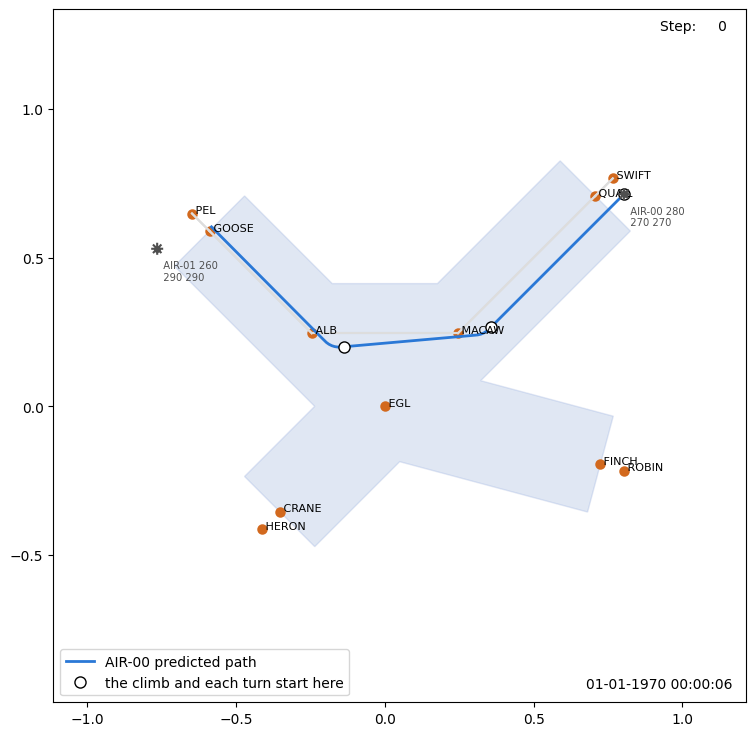

In [20]:
# a new simulator, and the aircraft to plan for
sim = make_sim()
environment = sim.manager.environment
aircraft = environment.aircraft["AIR-00"]

# the plan: one climb now, four turns right after 360 seconds, and five more 270 seconds after those
plan = repeat(climb, 1) + repeat(turn_right, 4, wait=360) + repeat(turn_right, 5, wait=270)

# predict where the plan takes the aircraft
path = rollout(sim, aircraft, plan)
print(describe(plan))
print(f"{predicted_outcome(environment, 'AIR-00', path)} at t {path[-1].time:.0f} s, FL{path[-1].fl:.0f}")

# the times at which the climb and each of the two turns start
starts = {when for (when, _), (wait, _) in zip(schedule(plan, environment.time), plan) if wait != STEP}

# draw the predicted path, and mark those times on it
ax = draw_radar(environment)
draw_path(ax, path, color=BLUE, label="AIR-00 predicted path")
draw_path(
    ax,
    [point for point in path if point.time in starts],
    color="black",
    marker="o",
    markersize=8,
    markerfacecolor="white",
    linestyle="",
    label="the climb and each turn start here",
)

ax.legend(loc="lower left")
plt.show()

The waits matter. Here the same plan is rolled out with different waits before the second turn.

In [21]:
# the same plan, with each wait from 150 to 420 seconds before the second turn
for wait in range(150, 421, 30):
    candidate = repeat(climb, 1) + repeat(turn_right, 4, wait=360) + repeat(turn_right, 5, wait=wait)
    outcome = predicted_outcome(environment, "AIR-00", rollout(sim, aircraft, candidate))

    print(f"second turn {wait} s after the first: {outcome}")

second turn 150 s after the first: wrong exit
second turn 180 s after the first: right exit
second turn 210 s after the first: right exit
second turn 240 s after the first: right exit


second turn 270 s after the first: right exit
second turn 300 s after the first: right exit
second turn 330 s after the first: right exit
second turn 360 s after the first: right exit


second turn 390 s after the first: right exit
second turn 420 s after the first: wrong exit


The second turn has to start between 180 and 390 seconds after the first. Earlier or later than that, the aircraft misses its exit gate.

Now we fly the plan in the simulator and compare where the aircraft goes with the prediction.

In [22]:
# the plan with its waits turned into times, and the positions the aircraft flies through
timed = schedule(plan, environment.time)
flown = []

# one step of the simulator for each step of the predicted path
for _ in path[1:]:
    # give the clearances the plan has due on this step
    aircraft = environment.aircraft["AIR-00"]
    sim.action([clearance(aircraft) for clearance in due(timed, environment.time)])

    sim.evolve(STEP)

    # note where the aircraft is now
    aircraft = environment.aircraft["AIR-00"]
    flown.append(Pos4D(aircraft.lat, aircraft.lon, aircraft.fl, environment.time))

# compare the flight with the prediction, point by point
print(f"largest difference in position: {max(a.distance(b) for a, b in zip(path[1:], flown)):.6f} NM")
print(f"largest difference in level: {max(abs(a.fl - b.fl) for a, b in zip(path[1:], flown)):.6f} FL")

# one more step, in which the simulator hands the aircraft over
sim.evolve(STEP)
print(f"t {environment.time:.0f} s: AIR-00 is now in {environment.aircraft['AIR-00'].current_sector!r}")

sim.close()

largest difference in position: 0.000000 NM
largest difference in level: 0.000000 FL
t 1008 s: AIR-00 is now in 'background'


The prediction and the flight agree exactly, and the simulator handed the aircraft over. That is why an agent can choose a plan from rollouts alone and then just follow it.

### An agent that chooses between plans

`PlanAgent` adds a second kind of candidate to `LookaheadAgent`: go to another level now, wait, and then go to the exit level. That is two level changes with a wait between them. The single level changes are tried first, then the two-part plans, starting with the levels nearest the current one.

In [23]:
class PlanAgent(LookaheadAgent):
    """A LookaheadAgent that can also send an aircraft to another level for a while."""

    # the levels an aircraft can be sent to on the way
    LEVELS = range(200, 360, 10)

    def candidate_plans(self, aircraft):
        """The single level changes first, then the plans that go by way of another level."""
        plans = super().candidate_plans(aircraft)

        start = aircraft.selected_fl
        end = self.environment.exit_coordination(SECTOR, aircraft.callsign).fl

        # try the levels nearest the current one first
        for via in sorted(self.LEVELS, key=lambda level: abs(level - start)):
            if via not in (start, end):
                # go to the other level now, and to the exit level after each wait
                plans += [level_change(start, via) + level_change(via, end, wait) for wait in self.WAITS[1:]]

        return plans


# fly an hour of traffic with the agent and add it to the results table
results["PlanAgent"] = run(PlanAgent)

show_results()
show_plans(results["PlanAgent"]["agent"])

agent               aircraft  right exit  wrong exit  pairs lost     seconds
NoAgent                   35           0          32           1         7.3
HeadingAgent              33          29           0           5         8.4
LookaheadAgent            33          29           0           1        11.7
PlanAgent                 33          29           0           0        19.0
69 rollouts for 33 aircraft; no candidate worked for none
plans that wait:
  AIR-05, planned at t 546 s: wait 540 s, climb x1
  AIR-08, planned at t 888 s: wait 60 s, climb x10
  AIR-17, planned at t 1962 s: wait 180 s, descend x10
  AIR-20, planned at t 2166 s: wait 360 s, descend x7
  AIR-25, planned at t 2478 s: climb x1, wait 420 s, descend x1


AIR-25 now climbs 10 flight levels out of the way, waits 420 seconds and comes back down, and no pair loses separation in this hour.

## Conclusions

Without the gym, the loop is short: read `sim.manager.environment`, build `Action` objects, give them to `sim.action` and call `sim.evolve`. A step takes less than 10 ms, so an agent can afford to roll out many candidate plans before it gives a clearance, and the rollout uses the simulator's own predictor and pilot, so what it predicts is what happens.

Some things to try:

- Run other seeds, for example `run(PlanAgent, seed=1)`. With that seed one pair still loses separation, because no candidate works for one aircraft.
- Add turns to the candidate plans, such as turning 20° away from the route for a few minutes and back. The plans of these agents only change level, because the turn rule does the steering.
- Choose the best candidate by some score, such as the fewest clearances or the shortest time in the sector. The agents here take the first candidate that works.
- Plan again for an earlier aircraft when a new one cannot be fitted in. Here the first aircraft to appear always keeps its plan.
- Use other kinds of `Action`, such as `route_direct_to`, which sends an aircraft straight to a fix on its route. From there the aircraft follows the rest of its route by itself. That is route following, which the four clearances cannot give.